In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import numpy as np
import seaborn as sns


# Data and data import

In [2]:
data_path = r"data/EnergyReport 25nov-26nov.xlsx"

if not os.path.exists(data_path):
    raise FileNotFoundError("Could NOT find: %s" % data_path)

energy_report = pd.read_excel(data_path)

print(energy_report.info())
print(energy_report.head())

<class 'pandas.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   TimeUTC      35040 non-null  str    
 1   TimeDK       35040 non-null  str    
 2   DK1_DKK/MWh  35040 non-null  float64
dtypes: float64(1), str(2)
memory usage: 821.4 KB
None
               TimeUTC               TimeDK  DK1_DKK/MWh
0  2025-10-31 23:00:00  2025-11-01 00:00:00   444.402812
1  2025-10-31 23:15:00  2025-11-01 00:15:00   375.326587
2  2025-10-31 23:30:00  2025-11-01 00:30:00   355.910582
3  2025-10-31 23:45:00  2025-11-01 00:45:00   326.637213
4  2025-11-01 00:00:00  2025-11-01 01:00:00   347.845481


# Date correction

In [3]:
energy_report["TimeDK"] = pd.to_datetime(energy_report["TimeDK"], format="%Y-%m-%d %H:%M:%S")
energy_report["TimeUTC"] = pd.to_datetime(energy_report["TimeUTC"], format="%Y-%m-%d %H:%M:%S")

print(energy_report.info())
print(energy_report.head())

<class 'pandas.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   TimeUTC      35040 non-null  datetime64[us]
 1   TimeDK       35040 non-null  datetime64[us]
 2   DK1_DKK/MWh  35040 non-null  float64       
dtypes: datetime64[us](2), float64(1)
memory usage: 821.4 KB
None
              TimeUTC              TimeDK  DK1_DKK/MWh
0 2025-10-31 23:00:00 2025-11-01 00:00:00   444.402812
1 2025-10-31 23:15:00 2025-11-01 00:15:00   375.326587
2 2025-10-31 23:30:00 2025-11-01 00:30:00   355.910582
3 2025-10-31 23:45:00 2025-11-01 00:45:00   326.637213
4 2025-11-01 00:00:00 2025-11-01 01:00:00   347.845481


# Visualise data

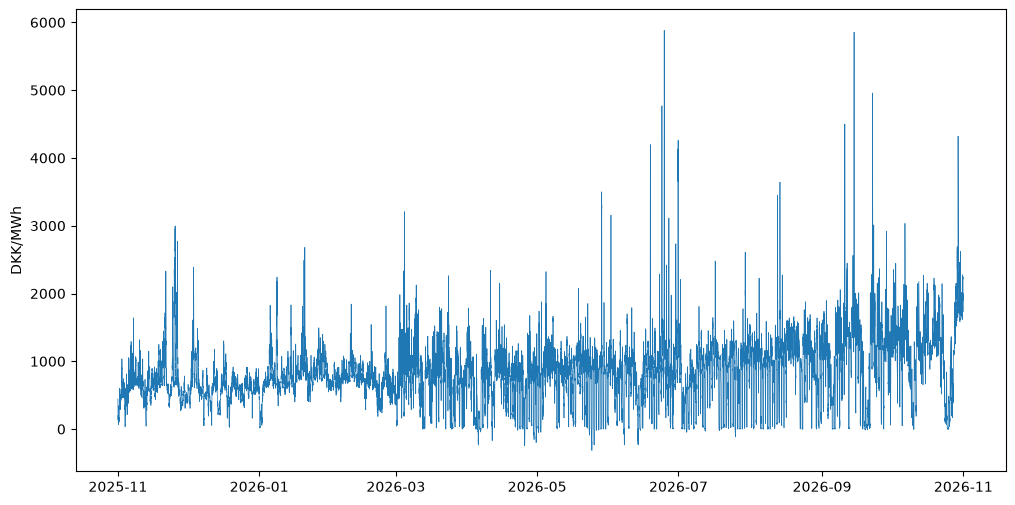

In [4]:
fig, ax = plt.subplots(figsize=(12,6))
ax.plot(
    energy_report.TimeDK, energy_report["DK1_DKK/MWh"],
    linewidth=0.5,
)

ax.set_ylabel("DKK/MWh")
plt.show()

# Including tarifs and other expenses

### Konstant Tariffer

Sommer/Vinter periode  
|Lastperiode     | 00:00-05:59 | 06:00-16:59 | 17:00-20:59 | 21:00-23:59 |  
|----------------|-------------|------------|------------|--------|
|Vinter oct-mar  | Lav         | Høj        | Spids      | Høj|  
|Sommer apr-sep  | Lav         | Høj        | Spids      | Høj|  
  
  
Sommer/Vinter tarif  
|Nettarif   |     Lav    |     Høj   |      Spids|  
|-----------|------------|-----------|-----------|
|Vinter     |     4.94   |     14.84 |      44.53|  
|Sommer     |     4.94   |     7.42  |      19.29|  
  
*priser er i øre/kWh  
  
Forbrugsabonnement      362.02 kr/år  
  
### Energinet Tariffer
|Beskrivelse            | Pris         |
|-----------------------|--------------|
|Systemtarif            | 7.20 øre/kWh |  
|Transmissionsnettarif  | 4.30 øre/kWh |  
|Systemabonnement       | 187.00 kr/år |  
  
  
**alle priser er ekskl. moms  

In [5]:
# Creating mask
idx = energy_report["TimeDK"]

# 1. Extracting calendar features
month = idx.dt.month
hour = idx.dt.hour

# 2. Define season masks
winter = month.isin([10, 11, 12, 1, 2, 3])  # october to march
summer = month.isin([4, 5, 6, 7, 8, 9])  # april to september

# 3. Define low, mid and high time periods
low = (hour >= 0) & (hour < 6)
high = ((hour >= 6) & (hour < 17)) | ((hour >= 21) & (hour < 24))
peak = (hour >= 17) & (hour < 21)

# 4. Combining conditions into mask
conditions = [
    winter & low,
    winter & high,
    winter & peak,
    summer & low,
    summer & high,
    summer & peak,
]

rates = [
    4.94,  # winter low
    14.84,  # winter high
    44.53,  # winter peak
    4.94,  # summer low
    7.42,  # summer high
    19.29,  # summer peak
]

hourly_tarif = pd.Series(
    np.select(conditions, rates, default=0.0),
    index=idx,
    name="hourly",
)

print(hourly_tarif.head())

TimeDK
2025-11-01 00:00:00    4.94
2025-11-01 00:15:00    4.94
2025-11-01 00:30:00    4.94
2025-11-01 00:45:00    4.94
2025-11-01 01:00:00    4.94
Name: hourly, dtype: float64


In [6]:
# 5. Tarif 
system_tarif = pd.Series([7.2]*len(idx), index=idx, name="system")
transmission_tarif = pd.Series([4.3]*len(idx), index=idx, name="transmission")

tarif = pd.concat([hourly_tarif, system_tarif, transmission_tarif], axis=1)

print(tarif.head())
print(energy_report.head())

                     hourly  system  transmission
TimeDK                                           
2025-11-01 00:00:00    4.94     7.2           4.3
2025-11-01 00:15:00    4.94     7.2           4.3
2025-11-01 00:30:00    4.94     7.2           4.3
2025-11-01 00:45:00    4.94     7.2           4.3
2025-11-01 01:00:00    4.94     7.2           4.3
              TimeUTC              TimeDK  DK1_DKK/MWh
0 2025-10-31 23:00:00 2025-11-01 00:00:00   444.402812
1 2025-10-31 23:15:00 2025-11-01 00:15:00   375.326587
2 2025-10-31 23:30:00 2025-11-01 00:30:00   355.910582
3 2025-10-31 23:45:00 2025-11-01 00:45:00   326.637213
4 2025-11-01 00:00:00 2025-11-01 01:00:00   347.845481


In [7]:
# Concat all data together
el_pris = energy_report.set_index(idx)
el_pris = el_pris.drop(["TimeUTC", "TimeDK"], axis=1)
el_pris = el_pris.rename(columns={"DK1_DKK/MWh": "øre_kwh"})

el_pris = el_pris["øre_kwh"]*0.1

data = pd.concat([el_pris, tarif], axis=1)

data["total_ex_vat"] = data["øre_kwh"] + data.hourly + data.system + data.transmission
data["total_in_vat"] = data["total_ex_vat"] * 1.25
print(data.head())

                       øre_kwh  hourly  system  transmission  total_ex_vat  \
TimeDK                                                                       
2025-11-01 00:00:00  44.440281    4.94     7.2           4.3     60.880281   
2025-11-01 00:15:00  37.532659    4.94     7.2           4.3     53.972659   
2025-11-01 00:30:00  35.591058    4.94     7.2           4.3     52.031058   
2025-11-01 00:45:00  32.663721    4.94     7.2           4.3     49.103721   
2025-11-01 01:00:00  34.784548    4.94     7.2           4.3     51.224548   

                     total_in_vat  
TimeDK                             
2025-11-01 00:00:00     76.100352  
2025-11-01 00:15:00     67.465823  
2025-11-01 00:30:00     65.038823  
2025-11-01 00:45:00     61.379652  
2025-11-01 01:00:00     64.030685  


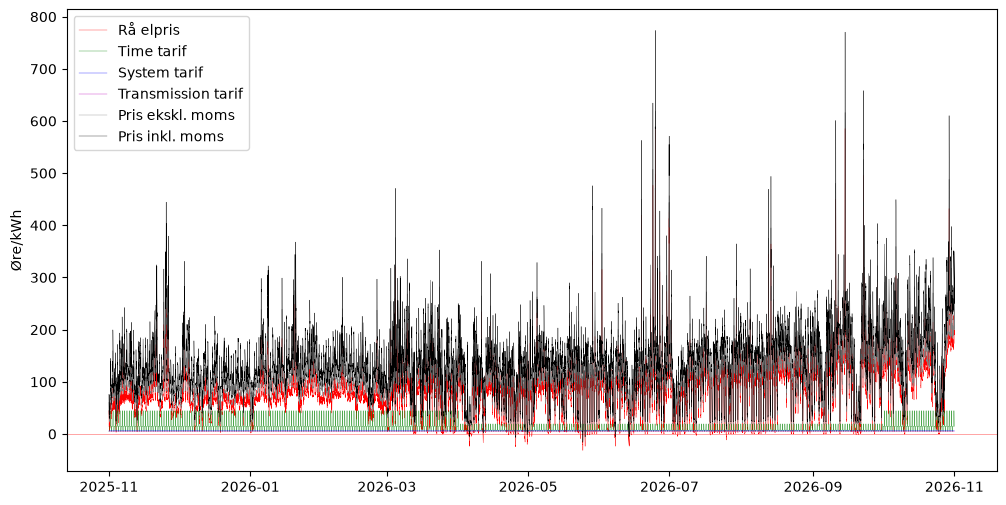

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(data.index, data["øre_kwh"], color='r', linewidth=0.25, label="Rå elpris")
ax.plot(data.index, data.hourly, color='g', linewidth=0.25, label="Time tarif")
ax.plot(data.index, data.system, color='b', linewidth=0.25, label="System tarif")
ax.plot(data.index, data.transmission, color='m', linewidth=0.25, label="Transmission tarif")

ax.plot(data.index, data.total_ex_vat, color='gray', linewidth=0.25, label="Pris ekskl. moms")
ax.plot(data.index, data.total_in_vat, color='k', linewidth=0.25, label="Pris inkl. moms")

ax.axhline(y=0, color='r', alpha=0.5, linewidth=0.5)

ax.set_ylabel("Øre/kWh")
ax.legend()
plt.show()